# K-Means Clustering: Can Universities Be Grouped into Private and Public?

The dataset describes 777 US colleges with 17 numeric features (applications, tuition, graduation rate, …).
K-Means is **unsupervised**: it never sees the `Private` label. Here the label is known, so I can check
how well the clusters it finds match the real private/public split.

**Tools:** pandas, seaborn, scikit-learn (`KMeans`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_style('whitegrid')

## 1. Data

In [2]:
df = pd.read_csv('data/college_data.csv', index_col=0)
df.head()

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
Abilene Christian University,Yes,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
Adelphi University,Yes,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
Adrian College,Yes,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
Agnes Scott College,Yes,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
Alaska Pacific University,Yes,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 777 entries, Abilene Christian University to York College of Pennsylvania
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Private      777 non-null    str    
 1   Apps         777 non-null    int64  
 2   Accept       777 non-null    int64  
 3   Enroll       777 non-null    int64  
 4   Top10perc    777 non-null    int64  
 5   Top25perc    777 non-null    int64  
 6   F.Undergrad  777 non-null    int64  
 7   P.Undergrad  777 non-null    int64  
 8   Outstate     777 non-null    int64  
 9   Room.Board   777 non-null    int64  
 10  Books        777 non-null    int64  
 11  Personal     777 non-null    int64  
 12  PhD          777 non-null    int64  
 13  Terminal     777 non-null    int64  
 14  S.F.Ratio    777 non-null    float64
 15  perc.alumni  777 non-null    int64  
 16  Expend       777 non-null    int64  
 17  Grad.Rate    777 non-null    int64  
dtypes: float64(1),

In [4]:
df.describe()

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.00000
mean,3001.638353,2018.804376,779.972973,27.558559,55.796654,3699.907336,855.298584,10440.669241,4357.526384,549.380952,1340.642214,72.660232,79.702703,14.089704,22.743887,9660.171171,65.46332
std,3870.201484,2451.113971,929.176190,17.640364,19.804778,4850.420531,1522.431887,4023.016484,1096.696416,165.105360,677.071454,16.328155,14.722359,3.958349,12.391801,5221.768440,17.17771
min,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,250.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.00000
25%,776.000000,604.000000,242.000000,15.000000,41.000000,992.000000,95.000000,7320.000000,3597.000000,470.000000,850.000000,62.000000,71.000000,11.500000,13.000000,6751.000000,53.00000
50%,1558.000000,1110.000000,434.000000,23.000000,54.000000,1707.000000,353.000000,9990.000000,4200.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8377.000000,65.00000
75%,3624.000000,2424.000000,902.000000,35.000000,69.000000,4005.000000,967.000000,12925.000000,5050.000000,600.000000,1700.000000,85.000000,92.000000,16.500000,31.000000,10830.000000,78.00000
max,48094.000000,26330.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.00000


## 2. Exploratory analysis

<Axes: xlabel='Room.Board', ylabel='Grad.Rate'>

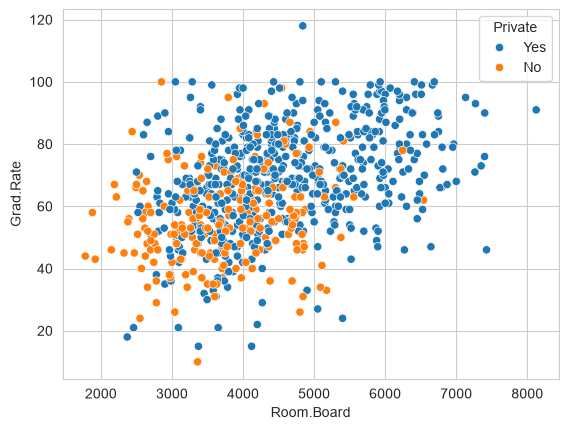

In [5]:
sns.scatterplot(data=df, x='Room.Board', y='Grad.Rate', hue='Private')

<Axes: xlabel='Outstate', ylabel='F.Undergrad'>

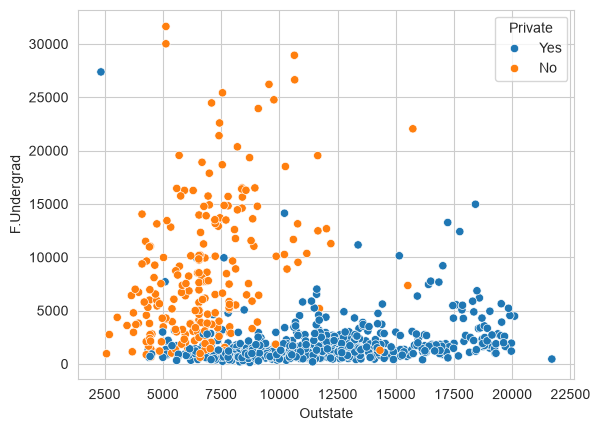

In [6]:
sns.scatterplot(data=df, x='Outstate', y='F.Undergrad', hue='Private')

Private schools tend to have **higher out-of-state tuition** and **fewer full-time undergraduates**.

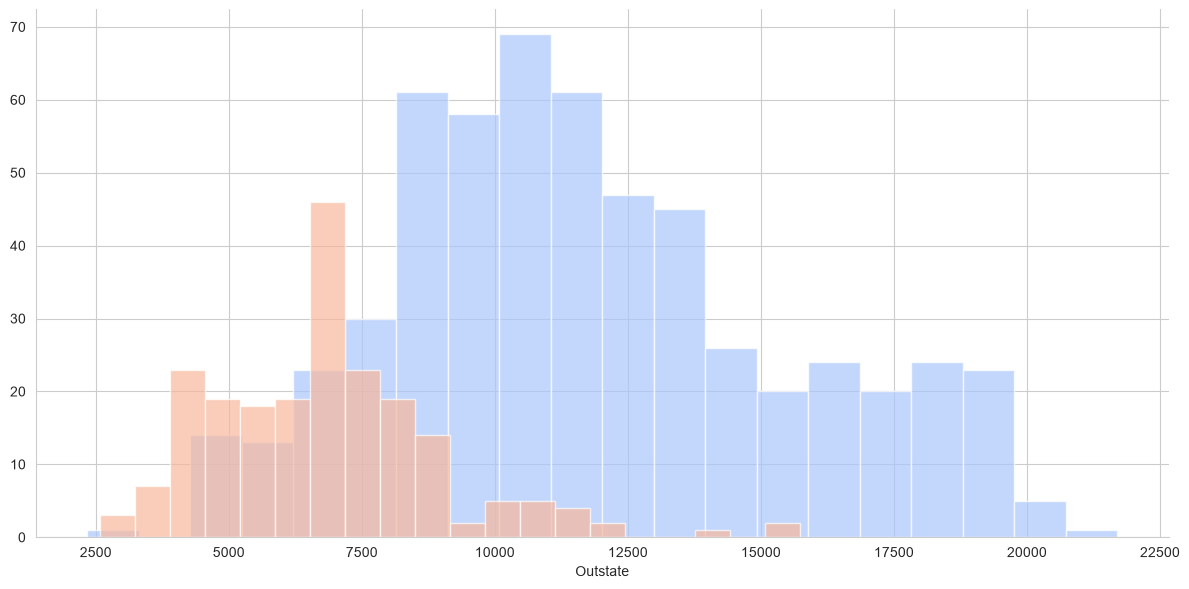

In [7]:
g = sns.FacetGrid(df, hue='Private', palette='coolwarm', height=6, aspect=2)
g = g.map(plt.hist, 'Outstate', bins=20, alpha=0.7)

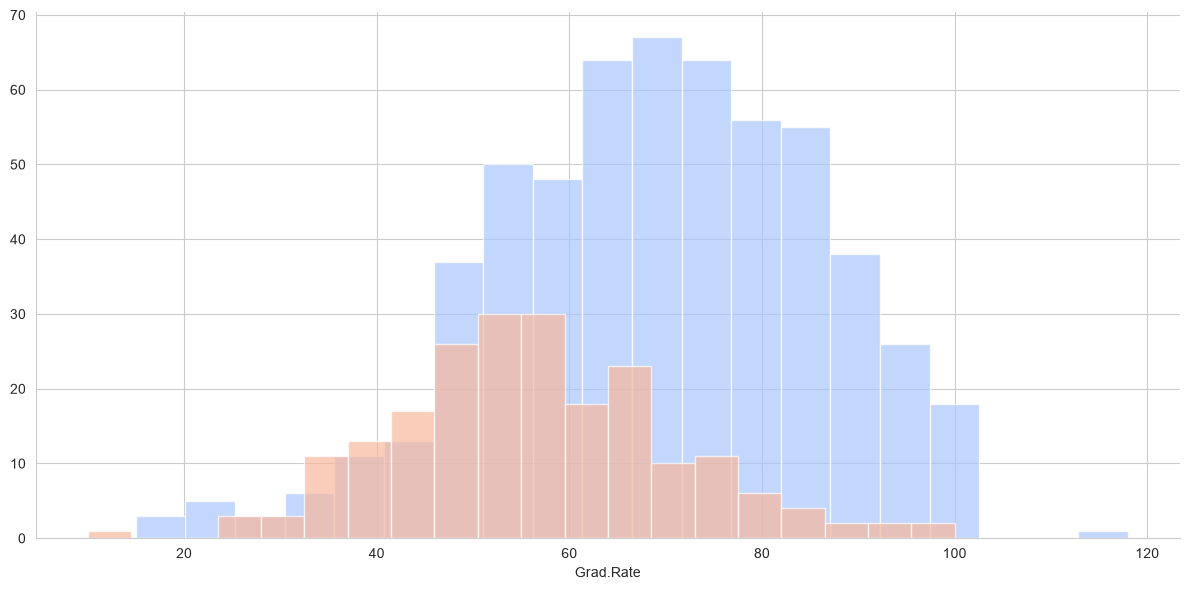

In [8]:
g = sns.FacetGrid(df, hue='Private', palette='coolwarm', height=6, aspect=2)
g = g.map(plt.hist, 'Grad.Rate', bins=20, alpha=0.7)

### Data cleaning
A graduation rate cannot be above 100%, but one school has such a value:

In [9]:
df[df['Grad.Rate'] > 100]

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
Cazenovia College,Yes,3847,3433,527,9,35,1010,12,9384,4840,600,500,22,47,14.3,20,7697,118


In [10]:
df.loc['Cazenovia College', 'Grad.Rate'] = 100
df[df['Grad.Rate'] > 100]

,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate


## 3. K-Means with 2 clusters

In [11]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, n_init=10, random_state=101)
kmeans.fit(df.drop('Private', axis=1))
kmeans.cluster_centers_

array([[1.81323468e+03, 1.28716592e+03, 4.91044843e+02, 2.53094170e+01,
        5.34708520e+01, 2.18854858e+03, 5.95458894e+02, 1.03957085e+04,
        4.31136472e+03, 5.41982063e+02, 1.28033632e+03, 7.04424514e+01,
        7.78251121e+01, 1.40997010e+01, 2.31748879e+01, 8.93204634e+03,
        6.50926756e+01],
       [1.03631389e+04, 6.55089815e+03, 2.56972222e+03, 4.14907407e+01,
        7.02037037e+01, 1.30619352e+04, 2.46486111e+03, 1.07191759e+04,
        4.64347222e+03, 5.95212963e+02, 1.71420370e+03, 8.63981481e+01,
        9.13333333e+01, 1.40277778e+01, 2.00740741e+01, 1.41705000e+04,
        6.75925926e+01]])

## 4. Comparing clusters with the real labels

Cluster numbers (0/1) are arbitrary, so I first check which cluster corresponds to private schools.

In [12]:
def converter(cluster):
    if cluster == 'Yes':
        return 1
    else:
        return 0

df['Cluster'] = df['Private'].apply(converter)
pd.crosstab(df['Private'], kmeans.labels_, rownames=['Private'], colnames=['K-Means cluster'])

K-Means cluster,0,1
Private,,
No,138,74
Yes,531,34


In [13]:
from sklearn.metrics import confusion_matrix, classification_report

# Map each cluster to the label that is most common inside it
mapping = df.groupby(kmeans.labels_)['Cluster'].agg(lambda s: s.mode()[0]).to_dict()
mapped = pd.Series(kmeans.labels_, index=df.index).map(mapping)
print('Cluster -> label mapping:', mapping)
print(confusion_matrix(df['Cluster'], mapped))
print(classification_report(df['Cluster'], mapped))

Cluster -> label mapping: {0: 1, 1: 0}
[[ 74 138]
 [ 34 531]]
              precision    recall  f1-score   support

           0       0.69      0.35      0.46       212
           1       0.79      0.94      0.86       565

    accuracy                           0.78       777
   macro avg       0.74      0.64      0.66       777
weighted avg       0.76      0.78      0.75       777



## 5. Conclusion

- After matching each cluster to its majority label, K-Means agrees with the real private/public split for **78%** of colleges, without ever seeing the label.
- It recognises **private** colleges well (recall 0.94) but puts most **public** colleges into the "private" cluster too (recall 0.35).
- The reason: features were **not scaled**, so variables with large values (applications, enrolment, expenditure)
  dominate the distance. The algorithm mainly separated **large** universities from **small** ones, and only large
  public universities ended up in their own cluster.

**Possible next steps:** standardise the features before clustering, use the elbow / silhouette method to choose the
number of clusters, and visualise the clusters in two dimensions with PCA.